# A coiled ring, two accounts

**Working notebook by Codex · 2026-10-25.** Ideas and teaching direction from dr. kraemer.

Imagine winding a spring around a doughnut, then joining the wire's ends. Following
that one wire takes you **once around the central hole** and **25 times around the
tube**. It is one closed circuit. A source keeps **2 ampere** flowing through it.
A rigid, nonmagnetic support holds its shape.

The distance from the ring's center to the tube's center is **10 hand**. The tube's
own radius is **2 hand**. A shaft passes through the center along a diameter and
turns the whole ring. A steady, uniform external magnetic field points up.

We will find the turning effect about the shaft in two ways: first by adding the
forces on the wire, then by following the change in linked flux.

**Linked flux** is what a voltage-time measurement tracks as a circuit moves:
one volt accumulated for one second records a change of one weber. Here the field
is uniform, so we can also calculate that quantity from the circuit's shadow.
All flux readings refer to the imposed external field. Its strength is **1 tesla**
in SI notation, **1 tesla·stroke** in the book's ledger.

In [1]:
from dataclasses import replace
import numpy as np
from IPython.display import display, HTML, Image, Markdown

from ring import Ring, state_at, add_forces, follow_flux, area_arrow, torque_about_shaft
from units import q
from view import RingView
from panel import explore
from comparison import comparison_at

# The knobs: quantities carry their units into the numerical model here.
case = Ring(radius=(10, 'hand'), tube=(2, 'hand'), windings=25,
            current=(2, 'ampere'), field=(1, 'tesla * stroke'),
            sweep=(1, 'sweep'), heading=(0, 'stroke'))
view = RingView()
three_four_five = np.arccos(4/5)

## First, read the picture

1. The copper line is the **one wire**. The many small loops are parts of it.
2. The gray arrows show the **field**. They all point the same way and have the
   same strength everywhere. The left view shows the shaft through the ring.
3. The right view looks **along the field**, as if a light shone that way and cast
   the wire's shadow on a screen. Turning the ring changes that shadow.
4. To count area, follow the wire in a chosen sense. A patch wound around the
   other way subtracts area. Two overlapping patches can therefore cancel even
   though both are visible. This is the **signed shadow area**.

In a uniform field, signed shadow area times field strength gives linked flux.
The blue arrow is a compact record of the whole winding's areas as seen from
three perpendicular directions. We call it its **area arrow**. It turns along
with the wire. The picture starts at home, with that arrow pointing along the field.

A still is one Python call:

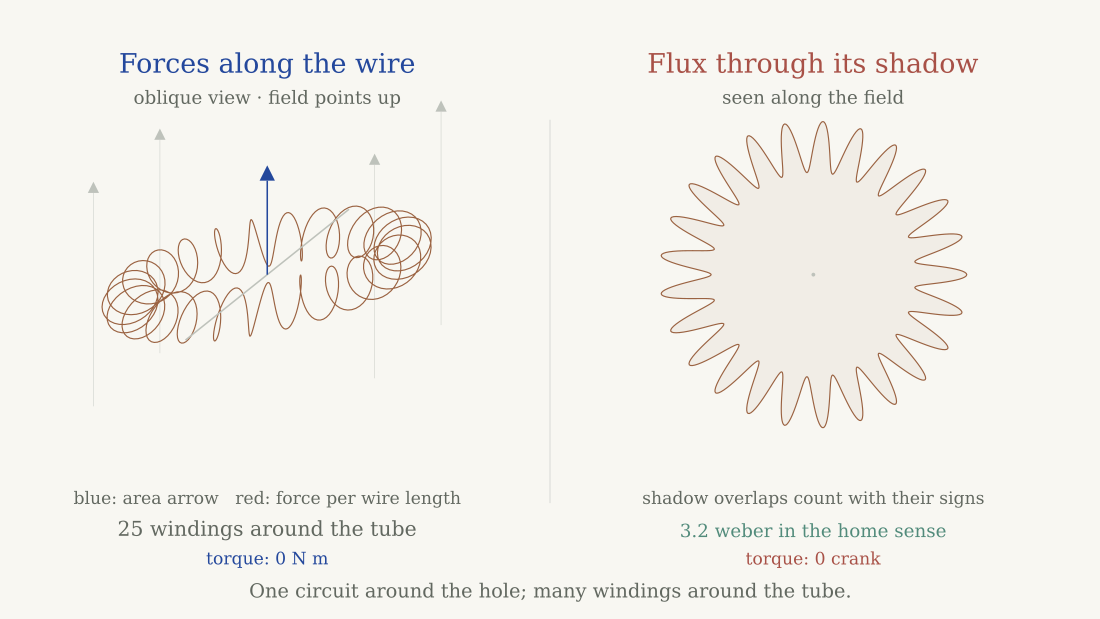

In [2]:
view.still(case, 0, forces=False)

## The problem

Turn the ring to the **3–4–5 pose**. Its area direction $\hat{\mathbf n}$ now has a
**forward part** $\rightarrow\!\cdot\hat{\mathbf n}=4/5$ along its home direction and
an **upward part** $\uparrow\!\cdot\hat{\mathbf n}=3/5$ along the other direction in
the plane of this turn. These two reference directions turn with the heading;
they describe parts of the direction arrow, rather than geographical directions.

Find the net push and the **torque about the shaft** in two ways. Then try
**36 windings**, change the shaft's heading, and reverse the current.

The shaft carries torque as twist. In the controls, red arrows show the force
per unit wire length. Both accounts report the torque's size and sense.

The saved animation makes a prescribed turn at one sweep. The shaft's drive
balances the magnetic torque to maintain that motion. The notebook measures that
torque during a prescribed turn.

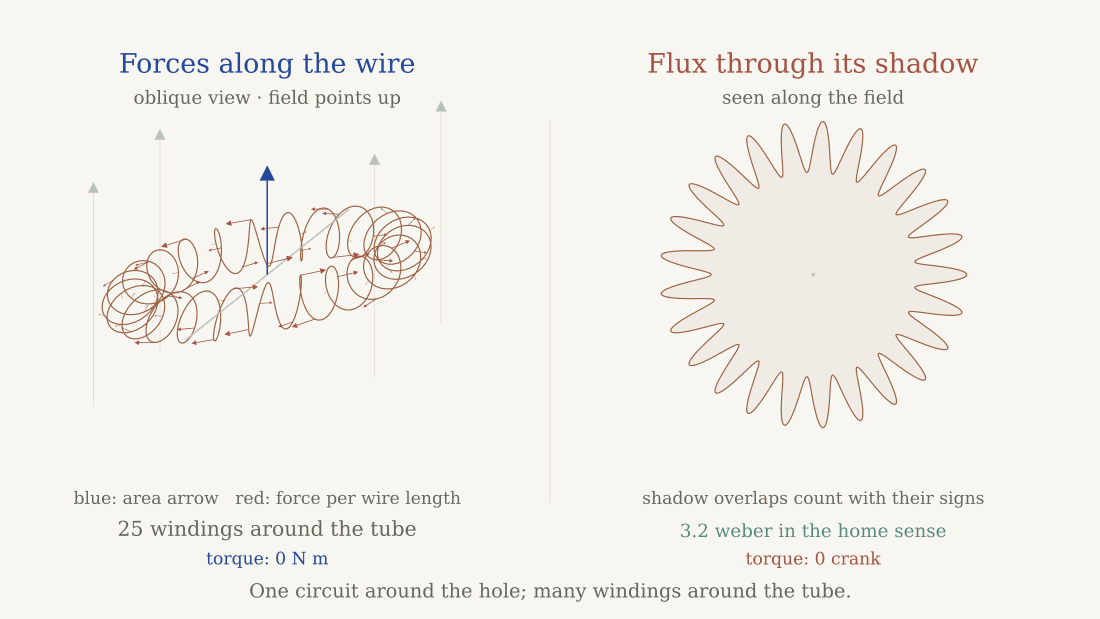

In [3]:
Image(filename='preview/coiled-ring.gif', format='gif')

Run this cell to connect the controls. **Heading** carries the shaft around the
field; **angle** turns the ring about that shaft. Together they let the area arrow
point throughout three dimensions. Changing the current or winding count keeps
the pose. The **3–4–5** button gives the exact pose without matching slider digits.

In [4]:
panel = explore(case, view)
panel

## What the balance says

Give the ring a small turn $d\theta$. Call its torque about the shaft $T$.
The mechanical work delivered during that turn is $T\,d\theta$.

During the same turn, the circuit gains some linked flux, $d\Phi$. With current
$I$ held fixed, the electrical account gives the mechanical work as $I\,d\Phi$.
These are two accounts of the same work:

$$T\,d\theta=I\,d\Phi.$$

The $d$ marks a change during the turn. To find the flux change, follow the area
arrow as it **sweeps about the shaft**. The part of that sweep along the field
tells us how much linked flux changes. Multiplying by current gives the mechanical
work; torque measures that work per stroke. A crank is a thump per stroke.

## The two accounts, side by side

In the usual column $b$ is the ordinary SI field and angles count radians.
The book's torque reading is in crank. The stroke bookkeeping appears in the
units section below.

| | Usual · add the forces | Straightforward · follow the flux |
| :-- | :-- | :-- |
| Follow the winding | With $u$ running from $0$ to $2\pi$, write $\rho=R+a\cos(Nu)$ and $\mathbf r=(\rho\cos u,\rho\sin u,a\sin Nu)$. Rotate all its pieces into the chosen pose. | Measure the wire's three signed shadows once. They make one **area arrow**. A rigid turn carries that arrow along with the winding. |
| Add the effect | $d\mathbf F=I\,d\mathbf r\times\mathbf b$. Add $d\mathbf F$ and $\mathbf r\times d\mathbf F$ around the wire. | Look along the field. Signed shadow area times field strength gives linked flux. Follow the area arrow's sweep about the shaft to find how that flux changes. |
| Turn the handle | Integration gives $A_0=\pi(R^2+a^2/2)$ for this winding, $N\ge2$. At heading zero, $\tau_y=-IbA_0\sin\theta$. | **Current × flux gained = mechanical work delivered.** Thus $T\,d\theta=I\,d\Phi$, and torque is the flux gained per stroke, times current. |
| The net push | $I(\oint d\mathbf r)\times\mathbf b=0$. The individual forces cancel. | Translating the closed ring in a uniform field changes no linked flux. There is no net push to extract by translation. |
| Try another axis | Repeat the vector sum; all three moment components are available. | The whole leverage follows from the area arrow and the field. Project it onto the shaft for torque; the remainder is an across-shaft moment. |

The straightforward account needs the signed area, which can be measured from a
shadow or calculated from the wire. The computer sums little triangles to measure
it. It then works with the **whole arrow**, without looking up any wire force.

In the numerical geometry, let $\alpha$ count strokes and let $\hat{\mathbf s}$
point along the shaft. Its sweep gives

$$d\mathbf A=(\hat{\mathbf s}\times\mathbf A)\,d\alpha,
\qquad d\Phi=\mathbf b\cdot d\mathbf A.$$

Thus the numerical torque reading is $I\,\mathbf b\cdot
(\hat{\mathbf s}\times\mathbf A)$. The total moment has the numerical components
$I\,\mathbf A\times\mathbf b$. The code follows this sweep directly. The only
numerical approximation in this account is measuring the signed areas.

At heading zero, write $f$ for the forward part and $h$ for the upward part:

$$f=\rightarrow\!\cdot\hat{\mathbf n},\qquad
h=\uparrow\!\cdot\hat{\mathbf n},\qquad \zeta=1\,\mathrm{stroke}.$$

$$\Phi=\Phi_0 f,\qquad \zeta\,df=-h\,d\theta.$$

The mechanical balance stays spread out:

$$T\,d\theta=I\,d\Phi,
\qquad T\,\zeta=-I\,\Phi_0 h.$$

Here $I$ stays fixed. Induction gives $\mathcal E=-d\Phi/dt$; the mechanical power
is $-I\mathcal E=I\,d\Phi/dt$. With positive current, turning toward greater linked flux delivers
mechanical work. The source maintaining the current participates in the energy
exchange. These are shaft-work statements.

## An instant you can edit

This comparison is independent of the live controls above. Edit these givens and
run the cell. `state_at` evaluates the two accounts separately for the same pose.

In [5]:
my_case = replace(case, windings=36, heading=(1, 'stroke'))
my_angle = three_four_five
my_time = my_angle / my_case.values['sweep']
display(HTML(comparison_at(my_case, my_time)))

,Usual · add the forces,Straightforward · follow the flux
What gets added,"Forces on wire pieces, then their leverage",Signed shadow areas; flux gained by the area arrow’s sweep
Net push,0 N,0 push · a uniform field keeps the linked flux unchanged during translation
Torque about the shaft,3.8453 N m back toward alignment,3.8453 crank back toward alignment
Across-shaft moment,0 N m,0 crank
Total moment · world axes,"3.236 N m about x, positive sense; 2.078 N m about y, reverse sense","3.236 crank about x, positive sense; 2.078 crank about y, reverse sense"
Linked flux,not used,2.5635 weber in the home sense


## What comes out

For the original sizes, the face-on linked flux is about **3.2 weber**.
At the 3–4–5 pose, about **2.6 weber** remains linked. With 2 ampere, both accounts
give about **3.8 crank back toward alignment**, and zero net push.

The usual calculation gives this ring's effective area as

$$A_0=\pi\left(R^2+\frac{a^2}{2}\right).$$

For these evenly spaced windings, $N\ge2$, that expression contains no $N$.
The little windings' sideways area arrows cancel around the ring. The wire still
makes **one trip around the central hole**. Its finite thickness leaves the
$a^2/2$ correction. Changing 25 to 36 rearranges the individual forces while
leaving the total external torque unchanged, within the polygon error shown below.
Changing the tube radius changes the answer.

Ampère's walk and this calculation both keep track of a circuit's winding.
Here the cancellation also uses the specified symmetry and geometry. The linked
flux depends on the areas: changing the shape can change the answer while keeping
the same winding counts.

This is a calculation for the specified symmetric closed wire and a uniform
external field. Its one trip around the hole is part of the circuit geometry;
the return path of an actual power connection belongs in that geometry too.

### Torque, moments, and the bearings

A force on a wire piece can both push and turn the ring. Its turning effect about
the center is a **moment**. The part about the shaft is the **torque** in
$T\,d\theta=I\,d\Phi$. The shaft carries it as twist.

An across-shaft moment would try to tip the shaft; the bearings would balance it.
For this symmetric ring in a uniform field, that part is zero. Changing heading
can give the torque two world-axis components, while it still acts entirely about
the shaft. The live table separates these quantities.

## See the arithmetic agree

The usual account uses the smooth wire's analytic tangent. The flux account uses
straight segments joining sampled points and measures their signed shadows.
Doubling the segment count makes the shadow's area error about four times smaller.
The sweep is exact at the measured area, so this table tests the area measurement
alone.

The rows below give torque sizes, all **back toward alignment** for this positive
current. The difference compares complete moment vectors, including their senses.
This tests agreement beyond what the rounded readings can show.

In [6]:
rows = []
for pieces in (16, 32, 64, 128, 256, 512):
    trial = replace(case, samples_per_winding=pieces, heading=(1, 'stroke'))
    state = state_at(trial, three_four_five / trial.values['sweep'])
    difference = np.linalg.norm(state.forces.moment - state.flux.moment)
    force_torque = abs(torque_about_shaft(trial, state.forces.moment))
    flux_torque = abs(state.flux.torque)
    rows.append(f'<tr><td>{pieces}</td><td>{force_torque:.8f}</td>'
                f'<td>{flux_torque:.8f}</td><td>{difference:.3g}</td></tr>')
display(HTML('<table><tr><th>Pieces per winding</th><th>Force account</th>'
             '<th>Flux account</th><th>Moment difference · crank</th></tr>'
             + ''.join(rows) + '</table>'))

Pieces per winding,Force account,Flux account,Moment difference · crank
16,3.84530941,3.83941217,0.0059
32,3.84530941,3.84382113,0.00149
64,3.84530941,3.84493646,0.000373
128,3.84530941,3.84521612,9.33e-05
256,3.84530941,3.84528608,2.33e-05
512,3.84530941,3.84530358,5.83e-06


## The code behind the comparison

`add_forces` takes the current, the tangent of every wire piece, and the field,
then adds the forces and their leverage. `follow_flux` sweeps the whole area arrow
about the shaft and takes the part along the field. It calls no force routine.
The two accounts share the specified wire and field, and calculate the turning
effect independently.

This cell shows the actual functions being used.

In [7]:
import inspect
display(Markdown('```python\n' + inspect.getsource(add_forces) + '\n'
                 + inspect.getsource(follow_flux) + '\n```'))

```python
def add_forces(case, angle):
    """Usual account: I dr cross B, then r cross dF, along the whole wire."""
    points, tangent, du = winding(case)
    points, tangent = pose(points, case, angle), pose(tangent, case, angle)
    field = np.array([0., 0., case.values['field']])
    force_density = case.values['current'] * np.cross(tangent, field)
    pieces = force_density * du
    moment = np.sum(np.cross(points, pieces), axis=0)
    per_length = force_density / np.linalg.norm(tangent, axis=1)[:, None]
    return Forces(pieces.sum(axis=0), moment, points, per_length)

def follow_flux(case, angle):
    """The area arrow sweeps about the shaft; follow its flux directly."""
    area = pose(area_arrow(case), case, angle)
    field = np.array([0., 0., case.values['field']])
    current = case.values['current']
    swept_area = np.cross(shaft(case), area)
    torque = current * np.dot(field, swept_area)
    moment = current * np.cross(area, field)
    return Flux(float(np.dot(field, area)), moment, area, float(torque))

```

## The optional calculus drawer

The winding's $N$-fold rotational symmetry makes its sideways area components
cancel for $N\ge2$. Its axial area follows from

$$A_z=\frac12\oint(x\,dy-y\,dx)
     =\frac12\int_0^{2\pi}(R+a\cos Nu)^2\,du.$$

Here is SymPy doing that integral for 25 windings. The flux account above does its
own shadow measurement; it does **not** use this integral or its result.

In [8]:
import sympy as sp
u = sp.symbols('u', real=True)
R, a = sp.symbols('R a', positive=True)
integrand = (R + a*sp.cos(25*u))**2 / 2
area_exact = sp.integrate(integrand, (u, 0, 2*sp.pi))
display(sp.Eq(sp.Symbol('A_0'), sp.factor(area_exact)))

Eq(A_0, pi*(2*R**2 + a**2)/2)

## Units and checks

The little ledger is written one definition per line in `units.txt`. It starts
with an empty Pint registry, so every included name has an explicit definition.
You can enter lengths in hand, meter, foot, or inch. The same dimensions then meet
the numerical geometry at one boundary. The following work balance keeps its
stroke; a crank is a thump per stroke.

Write $\zeta=1\,\mathrm{stroke}$. The usual field is $\mathbf b$; the book field is
$\mathbf B=\zeta\mathbf b$. Each cross removes a stroke. The numerical routines
meet at this convention once. Torque comes out in
$\mathrm{crank}=\mathrm{thump}/\mathrm{stroke}$.

In [9]:
work = q(2, 'ampere') * q(3, 'weber')
torque = work / q(2, 'stroke')
display(HTML(f'{work.to("thump")} over 2 stroke gives <b>{torque.to("crank")}</b>.'))

Run `python -m pytest -q` in this folder for the independent checks: several
orientations and winding counts, the flat-ring limit, current reversal, flux/work
balance, refinement, equivalent length units, and the controls.

Conventional reference: [Feynman II, §15–1](https://www.feynmanlectures.caltech.edu/II_15.html)
for forces, torque, and the mechanical potential at maintained current; and
[II, §17–2](https://www.feynmanlectures.caltech.edu/II_17.html) for generator
power and induction. The winding calculation and numerical comparison are derived
in this notebook.

**Provenance · append only.** 2026-10-25 09:44 America/New_York — Codex wrote this
working notebook and its companion code at dr. kraemer's request. The paired
accounts, coiled ring, shared controls, and explicit comparison follow the user's
direction. It accompanies the earlier rotating-loop notebook.

**Provenance · appended 2026-10-25.** Claude's review, relayed by
dr. kraemer, checked the saved arithmetic and requested current direction-part
terms, a distinction between shaft torque and across-shaft moments, size-and-sense
readings, and delivery of the full runnable folder. Codex made those changes.
Following dr. kraemer's reminder about readers' starting points, this revision
introduces the wire, field, shadow, flux measurement, and work balance in stages.

**Provenance · appended 2026-10-25 10:18.** Claude's note, relayed by
dr. kraemer, requested the direct sweep in place of a finite difference. Codex
implemented the shaft-axis cross area, its flux change, and the whole moment
directly. The convergence table now tests the measured area alone. The force
account remains an independent calculation.